# Reproducing Figure 3 of Keskar et al. (ICLR 2017): F1, C1, C2

**Paper:** *On Large-Batch Training for Deep Learning: Generalization Gap and Sharp Minima.*

Figure 3 trains the same network twice — once with a **small batch (SB, 256)** and once with a **large batch (LB, 10% of the training set)**, both with Adam — and then walks the straight line between the two solutions:

$$
x(\alpha) = \alpha\, x^\star_\ell + (1-\alpha)\, x^\star_s, \qquad \alpha \in [-1, 2],
$$

so $\alpha = 0$ is the SB minimizer and $\alpha = 1$ is the LB minimizer. Along that line we record cross-entropy (blue, left axis) and accuracy (red, right axis) on train (solid) and test (dashed). The claim the figure supports: the basin around $\alpha=1$ is visibly **narrower** than the one around $\alpha=0$.

| Panel | Network | Data | Rough cost on one modern GPU (`BUDGET="paper"`) |
|---|---|---|---|
| F1 | 5×512 fully connected + BN | MNIST | a few minutes |
| C1 | shallow AlexNet-style conv | CIFAR-10 | ~10–20 min |
| C2 | VGG-16-style conv | CIFAR-10 | ~1–2 h |

Use `BUDGET="quick"` first to check everything works, then switch to `"paper"`. Trained models are cached in `CKPT_DIR`, so re-running the plotting cells is free.

**Notebook map:** setup → config → data → architectures (Appendix B) → training → interpolation (with a BatchNorm subtlety worth understanding) → the figure → optional: the paper's sharpness metric (Metric 2.1) → things to try.

In [1]:
# If you're on Colab, torch/torchvision are preinstalled. Otherwise:
# !pip install torch torchvision matplotlib

import os, time, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"          # fp16 autocast on CUDA: ~2x faster and ~half the activation memory
torch.backends.cudnn.benchmark = True
print(f"torch {torch.__version__} | device: {DEVICE}" +
      (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

torch 2.11.0+cu130 | device: cuda (Tesla T4)


## 1. Configuration

Everything that matters for the experiment is here. A few choices deserve a word:

- **Optimizer:** Adam, $\text{lr}=10^{-3}$, for *both* regimes — this is what the paper does (Section 2.2). Keep it in mind: holding the learning rate fixed while multiplying the batch by ~20 changes more than "the batch size" (see the last section).
- **Stopping:** the paper trains "until the loss function ceased to improve." We approximate that with a plateau rule on the epoch-average training loss, capped by `MAX_EPOCHS`.
- **Different seeds for SB and LB:** the paper starts each run from a different random point, so the two minimizers are not connected by construction. `SAME_INIT=True` is an interesting variation (see the end).
- **`BN_MODE`:** how to set BatchNorm statistics for an interpolated network — explained in Section 5.

In [2]:
SMOKE_TEST = os.environ.get("LBSB_SMOKE", "0") == "1"   # tiny synthetic run to check the plumbing; leave False

NETWORKS    = ["F1", "C1", "C2"]
DATASET_OF  = {"F1": "mnist", "C1": "cifar10", "C2": "cifar10"}

SB_BATCH    = 256          # paper: 256
LB_FRACTION = 0.10         # paper: 10% of the training set -> 6000 (MNIST), 5000 (CIFAR-10)
LR          = 1e-3         # Adam default, same for both regimes (as in the paper)

BUDGET = "paper"           # "quick" to sanity-check, "paper" to reproduce
MAX_EPOCHS = {"paper": {"F1": 100, "C1": 100, "C2": 100},
              "quick": {"F1": 15,  "C1": 30,  "C2": 20}}[BUDGET]
PATIENCE, REL_TOL, ABS_TOL = 10, 0.01, 1e-3   # stop if loss hasn't improved by max(1% rel, 1e-3 abs) in 10 epochs

SEEDS     = {"SB": 0, "LB": 1}
SAME_INIT = False          # True: LB starts from exactly the SB initialization

ALPHAS        = np.linspace(-1.0, 2.0, 31)   # step 0.1; includes 0 and 1 exactly
EVAL_TRAIN_N  = 10_000     # training points used to evaluate the train curve (None = full training set)
BN_MODE       = "recompute"  # "recompute" (recommended) or "interpolate"
BN_RECALIB_N  = 5_000      # training points used to re-estimate BN statistics at each alpha

DATA_ROOT = "./data"
CKPT_DIR  = f"./checkpoints_{BUDGET}"

if SMOKE_TEST:
    MAX_EPOCHS   = {k: 2 for k in NETWORKS}
    ALPHAS       = np.linspace(-1.0, 2.0, 7)
    EVAL_TRAIN_N = BN_RECALIB_N = 512
    CKPT_DIR     = "./checkpoints_smoke"
os.makedirs(CKPT_DIR, exist_ok=True)

## 2. Data

Both datasets fit comfortably in GPU memory, so we load them once as tensors and slice batches directly — much faster than a `DataLoader` at batch size 5000. Inputs are standardized with training-set mean/std (the paper says no preprocessing; standardization only changes the conditioning, not the comparison). No data augmentation: the paper's main experiments use none, and Appendix E shows augmentation shifts the numbers.

In [4]:
from datasets import load_dataset

In [5]:
def _standardize(Xtr, Xte):
    mean = Xtr.mean(dim=(0, 2, 3), keepdim=True)
    std  = Xtr.std(dim=(0, 2, 3), keepdim=True)
    return (Xtr - mean) / std, (Xte - mean) / std

def load_data(name):
    if SMOKE_TEST:  # random tensors with the right shapes
        g = torch.Generator().manual_seed(0)
        shape = (1, 28, 28) if name == "mnist" else (3, 32, 32)
        Xtr, Xte = torch.randn(5120, *shape, generator=g), torch.randn(512, *shape, generator=g)
        ytr, yte = torch.randint(0, 10, (5120,), generator=g), torch.randint(0, 10, (512,), generator=g)
    elif name == "mnist":
        # Add reliable mirrors to torchvision because the default server often rejects connections
        torchvision.datasets.MNIST.mirrors = [
            "https://ossci-datasets.s3.amazonaws.com/mnist/",
            "http://yann.lecun.com/exdb/mnist/"
        ]
        tr = torchvision.datasets.MNIST(DATA_ROOT, train=True,  download=True)
        te = torchvision.datasets.MNIST(DATA_ROOT, train=False, download=True)
        Xtr, Xte = tr.data.float().div(255).unsqueeze(1), te.data.float().div(255).unsqueeze(1)
        ytr, yte = tr.targets.clone(), te.targets.clone()
    elif name == "cifar10":
        hf_dataset = load_dataset("uoft-cs/cifar10")

        def to_numpy(split):
            imgs = np.stack([np.asarray(im) for im in split["img"]])
            labels = np.asarray(split["label"], dtype=np.int64)
            return imgs, labels

        train_imgs, train_labels = to_numpy(hf_dataset["train"])
        test_imgs,  test_labels  = to_numpy(hf_dataset["test"])

        # Convert numpy arrays to Torch tensors matching the original shape [N, C, H, W] and float range [0, 1]
        Xtr = torch.from_numpy(train_imgs).permute(0, 3, 1, 2).float().div(255)
        Xte = torch.from_numpy(test_imgs).permute(0, 3, 1, 2).float().div(255)
        ytr = torch.from_numpy(train_labels)
        yte = torch.from_numpy(test_labels)
    else:
        raise ValueError(name)
    Xtr, Xte = _standardize(Xtr, Xte)
    # fixed random subsets (same for every alpha) for train-curve evaluation and BN recalibration
    g = torch.Generator().manual_seed(123)
    perm = torch.randperm(len(ytr), generator=g)
    n_eval = len(ytr) if EVAL_TRAIN_N is None else min(EVAL_TRAIN_N, len(ytr))
    d = dict(Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte,
             eval_idx=perm[:n_eval], bn_idx=torch.randperm(len(ytr), generator=g)[:BN_RECALIB_N])
    return {k: v.to(DEVICE) for k, v in d.items()}

DATA = {}
for net in NETWORKS:
    ds = DATASET_OF[net]
    if ds not in DATA:
        DATA[ds] = load_data(ds)
        print(f"{ds}: train {tuple(DATA[ds]['Xtr'].shape)}, test {tuple(DATA[ds]['Xte'].shape)}")

mnist: train (60000, 1, 28, 28), test (10000, 1, 28, 28)


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

cifar10: train (50000, 3, 32, 32), test (10000, 3, 32, 32)


## 3. Architectures (Appendix B)

Read straight from Appendix B; where the appendix is silent I made the standard choice and flagged it in a comment.

- **F1:** 784 → 5 × [Linear(512) → BN → ReLU] → Linear(10).
- **C1:** 2 × [Conv(64, 5×5, stride 2) → BN → ReLU → MaxPool(3)] → Dense(384) → Dense(192) → 10, BN everywhere, dropout 0.5 on the two dense layers.
- **C2:** VGG-16 conv stack (2×64, 2×128, 3×256, 3×512, 3×512, 3×3 kernels, MaxPool(2) after each stack) → Dense(512) → 10, BN everywhere, dropout 0.5 on the dense layer.

Softmax lives inside `F.cross_entropy`, so the models output logits.

In [6]:
def make_F1():
    layers, d = [nn.Flatten()], 784
    for _ in range(5):
        layers += [nn.Linear(d, 512), nn.BatchNorm1d(512), nn.ReLU(inplace=True)]
        d = 512
    layers.append(nn.Linear(512, 10))
    return nn.Sequential(*layers)

def _dense(i, o):
    return [nn.Linear(i, o), nn.BatchNorm1d(o), nn.ReLU(inplace=True), nn.Dropout(0.5)]

def make_C1(n_classes=10):
    # Unstated in the paper: padding and MaxPool stride. 'same' padding and an overlapping
    # 3x3/stride-2 pool (AlexNet / TF CIFAR-10 style): 32 -> 16 -> 8 -> 4 -> 2, giving 64*2*2 features.
    return nn.Sequential(
        nn.Conv2d(3, 64, 5, stride=2, padding=2),  nn.BatchNorm2d(64), nn.ReLU(inplace=True),
        nn.MaxPool2d(3, stride=2, padding=1),
        nn.Conv2d(64, 64, 5, stride=2, padding=2), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
        nn.MaxPool2d(3, stride=2, padding=1),
        nn.Flatten(),
        *_dense(64 * 2 * 2, 384), *_dense(384, 192),
        nn.Linear(192, n_classes))

def make_C2(n_classes=10):
    cfg, layers, c = [(2, 64), (2, 128), (3, 256), (3, 512), (3, 512)], [], 3
    for reps, width in cfg:
        for _ in range(reps):
            layers += [nn.Conv2d(c, width, 3, padding=1), nn.BatchNorm2d(width), nn.ReLU(inplace=True)]
            c = width
        layers.append(nn.MaxPool2d(2))              # 32 -> 16 -> 8 -> 4 -> 2 -> 1
    return nn.Sequential(*layers, nn.Flatten(), *_dense(512, 512), nn.Linear(512, n_classes))

MODELS = {"F1": make_F1, "C1": make_C1, "C2": make_C2}
for k, f in MODELS.items():
    print(f"{k}: {sum(p.numel() for p in f().parameters()):,} parameters")

F1: 1,462,794 parameters
C1: 283,274 parameters
C2: 14,991,946 parameters


## 4. Training

One step of Equation (2) of the paper: sample a batch $B_k$ without replacement (a fresh permutation each epoch, fixed batch size), compute $\frac{1}{|B_k|}\sum_{i\in B_k}\nabla f_i$, and hand it to Adam.

**Memory and a hidden trap.** A batch of 5000 CIFAR images through the VGG stack may not fit on a small GPU. The code then automatically splits the batch into micro-batches and accumulates gradients. For the *loss*, that is exact — the gradient of an average is the average of gradients. But it is **not** exact for BatchNorm, which normalizes with statistics of whatever chunk it sees. Splitting turns "BN over 5000" into "BN over chunks of, say, 1250" (this is called *ghost batch norm*, and Hoffer et al. 2017 found it partly closes the generalization gap). So if you see the warning, your LB run is slightly less "large-batch" than the paper's. A GPU with ≥16 GB plus fp16 autocast usually avoids it.

In [7]:
def sgd_step(model, opt, scaler, xb, yb, micro):
    opt.zero_grad(set_to_none=True)
    B, loss_sum, correct = len(yb), 0.0, 0
    for s in range(0, B, micro):
        xc, yc = xb[s:s + micro], yb[s:s + micro]
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(xc)
        loss = F.cross_entropy(out.float(), yc, reduction="sum")
        scaler.scale(loss / B).backward()        # sum over chunks of (chunk sum / B) = batch mean
        loss_sum += loss.item()
        correct += (out.argmax(1) == yc).sum().item()
    scaler.step(opt)
    scaler.update()
    return loss_sum, correct

@torch.no_grad()
def evaluate(model, X, Y, bs=2000):
    model.eval()
    tot, corr = 0.0, 0
    for s in range(0, len(Y), bs):
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            out = model(X[s:s + bs])
        tot  += F.cross_entropy(out.float(), Y[s:s + bs], reduction="sum").item()
        corr += (out.argmax(1) == Y[s:s + bs]).sum().item()
    return tot / len(Y), 100.0 * corr / len(Y)

def train_model(net, regime, data):
    seed = SEEDS["SB"] if SAME_INIT else SEEDS[regime]
    torch.manual_seed(seed)
    model = MODELS[net]().to(DEVICE)
    N  = len(data["ytr"])
    bs = SB_BATCH if regime == "SB" else int(LB_FRACTION * N)
    opt    = torch.optim.Adam(model.parameters(), lr=LR)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    gen    = torch.Generator().manual_seed(1000 + seed)
    micro, hist, best, since = bs, [], math.inf, 0
    t0 = time.time()
    print(f"[{net}-{regime}] batch {bs}, {N // bs} steps/epoch, max {MAX_EPOCHS[net]} epochs")
    for epoch in range(1, MAX_EPOCHS[net] + 1):
        model.train()
        perm = torch.randperm(N, generator=gen).to(DEVICE)
        tot, corr, cnt = 0.0, 0, 0
        for i in range(N // bs):                      # drop the ragged last batch: |B_k| stays fixed
            idx = perm[i * bs:(i + 1) * bs]
            xb, yb = data["Xtr"][idx], data["ytr"][idx]
            while True:
                try:
                    l, c = sgd_step(model, opt, scaler, xb, yb, micro)
                    break
                except torch.cuda.OutOfMemoryError:
                    opt.zero_grad(set_to_none=True); torch.cuda.empty_cache()
                    if micro <= 128:
                        raise
                    micro //= 2
                    print(f"  ! OOM: splitting each batch of {bs} into micro-batches of {micro} "
                          f"(BatchNorm now sees {micro} samples: ghost-BN, see Section 4)")
            tot, corr, cnt = tot + l, corr + c, cnt + len(yb)
        ep_loss, ep_acc = tot / cnt, 100.0 * corr / cnt
        hist.append(dict(epoch=epoch, loss=ep_loss, acc=ep_acc))
        if epoch == 1 or epoch % 10 == 0:
            print(f"  epoch {epoch:3d}  train loss {ep_loss:.4f}  acc {ep_acc:6.2f}%  ({time.time() - t0:.0f}s)")
        if ep_loss < best - max(REL_TOL * best, ABS_TOL):
            best, since = ep_loss, 0
        else:
            since += 1
            if since >= PATIENCE:
                print(f"  plateau reached at epoch {epoch}")
                break
    sd = {k: v.detach().cpu() for k, v in model.state_dict().items()}
    return dict(state_dict=sd, history=hist, batch_size=bs, micro_batch=micro, seed=seed)

In [8]:
RESULTS = {}
for net in NETWORKS:
    data = DATA[DATASET_OF[net]]
    for regime in ["SB", "LB"]:
        path = os.path.join(CKPT_DIR, f"{net}_{regime}{'_sameinit' if SAME_INIT else ''}.pt")
        if os.path.exists(path):
            RESULTS[(net, regime)] = torch.load(path, map_location="cpu")
            print(f"[{net}-{regime}] loaded {path}")
        else:
            RESULTS[(net, regime)] = train_model(net, regime, data)
            torch.save(RESULTS[(net, regime)], path)

# Table 2-style summary. Compare training accuracy first: the comparison is only meaningful
# if BOTH regimes actually reached (near-)zero training error.
print(f"\n{'net':4s} {'regime':6s} {'epochs':>6s} {'train acc':>10s} {'test acc':>9s}")
for net in NETWORKS:
    data = DATA[DATASET_OF[net]]
    for regime in ["SB", "LB"]:
        r = RESULTS[(net, regime)]
        m = MODELS[net]().to(DEVICE); m.load_state_dict(r["state_dict"])
        _, tr_acc = evaluate(m, data["Xtr"], data["ytr"])
        _, te_acc = evaluate(m, data["Xte"], data["yte"])
        print(f"{net:4s} {regime:6s} {len(r['history']):6d} {tr_acc:9.2f}% {te_acc:8.2f}%")

[F1-SB] batch 256, 234 steps/epoch, max 100 epochs
  epoch   1  train loss 0.1806  acc  94.65%  (1s)
  epoch  10  train loss 0.0181  acc  99.43%  (10s)
  plateau reached at epoch 10
[F1-LB] batch 6000, 10 steps/epoch, max 100 epochs
  epoch   1  train loss 0.6444  acc  81.77%  (0s)
  epoch  10  train loss 0.0018  acc 100.00%  (1s)
  plateau reached at epoch 10
[C1-SB] batch 256, 195 steps/epoch, max 100 epochs
  epoch   1  train loss 1.5200  acc  44.43%  (3s)
  epoch  10  train loss 0.6058  acc  78.95%  (11s)
  plateau reached at epoch 10
[C1-LB] batch 5000, 10 steps/epoch, max 100 epochs
  epoch   1  train loss 2.0177  acc  26.52%  (1s)
  epoch  10  train loss 0.9210  acc  67.62%  (4s)
  plateau reached at epoch 10
[C2-SB] batch 256, 195 steps/epoch, max 100 epochs
  epoch   1  train loss 1.5445  acc  40.20%  (9s)
  epoch  10  train loss 0.1851  acc  93.72%  (85s)
  plateau reached at epoch 10
[C2-LB] batch 5000, 10 steps/epoch, max 100 epochs
  epoch   1  train loss 2.1220  acc  19.0

## 5. Interpolation — and why BatchNorm needs care

Linearly interpolating the **trainable** parameters is unambiguous. BatchNorm also carries **buffers** — running mean $\hat\mu$ and variance $\hat\sigma^2$ — and at evaluation time it computes $\gamma\,(z-\hat\mu)/\sqrt{\hat\sigma^2+\epsilon}+\beta$. What should $\hat\mu,\hat\sigma^2$ be for the network $x(\alpha)$?

The naive move is to interpolate them too. Let's check against the definition. Take the first layer, pre-activation $z = w^\top u$ for input $u$ with covariance $\Sigma$, and $w(\alpha) = (1-\alpha)w_s + \alpha w_\ell$:

- Mean: $\mathbb{E}[z] = (1-\alpha)\,w_s^\top\mathbb{E}u + \alpha\, w_\ell^\top\mathbb{E}u$ — linear in $\alpha$, so interpolating $\hat\mu$ is **correct**.
- Variance: $\mathrm{Var}[z] = w(\alpha)^\top\Sigma\, w(\alpha) = (1-\alpha)^2\sigma_s^2 + \alpha^2\sigma_\ell^2 + 2\alpha(1-\alpha)\,w_s^\top\Sigma w_\ell$ — **quadratic** in $\alpha$, so interpolating $\hat\sigma^2$ is wrong for every $\alpha\notin\{0,1\}$. If $w_s$ and $w_\ell$ are nearly orthogonal under $\Sigma$ (two independent runs!), at $\alpha=\tfrac12$ the true variance is about half the interpolated one.

And from the second layer on, even the mean is nonlinear in $\alpha$, because the input to that layer itself depends on $\alpha$ through a ReLU. Mis-normalized activations compound through depth and create a **fake loss barrier** that has nothing to do with the geometry of $f$.

So `BN_MODE="recompute"` sets the interpolated parameters, then re-estimates the BN statistics with forward passes over `BN_RECALIB_N` training points (dropout off), exactly the way SWA does it. Then the curve reflects the network you would actually deploy at $x(\alpha)$. Try `"interpolate"` once and compare — it's a nice demonstration of how an evaluation artifact can masquerade as a geometric fact.

In [9]:
def interpolate_state(sd_s, sd_l, alpha):
    out = {}
    for k, vs in sd_s.items():
        vl = sd_l[k]
        out[k] = (1 - alpha) * vs + alpha * vl if vs.is_floating_point() else vs.clone()
    return out

@torch.no_grad()
def recalibrate_bn(model, X, bs=500):
    bns = [m for m in model.modules() if isinstance(m, nn.modules.batchnorm._BatchNorm)]
    if not bns:
        return
    for m in bns:
        m.reset_running_stats()
        m.momentum = None                     # cumulative average over all recalibration batches
    model.train()
    for m in model.modules():
        if isinstance(m, nn.Dropout):
            m.eval()                          # recalibrate the deterministic network
    for s in range(0, len(X), bs):
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            model(X[s:s + bs])
    for m in bns:
        m.momentum = 0.1
    model.eval()

def interpolation_curve(net):
    data  = DATA[DATASET_OF[net]]
    sd_s  = {k: v.to(DEVICE) for k, v in RESULTS[(net, "SB")]["state_dict"].items()}
    sd_l  = {k: v.to(DEVICE) for k, v in RESULTS[(net, "LB")]["state_dict"].items()}
    Xe, Ye = data["Xtr"][data["eval_idx"]], data["ytr"][data["eval_idx"]]
    Xbn    = data["Xtr"][data["bn_idx"]]
    model  = MODELS[net]().to(DEVICE)
    curve  = {k: [] for k in ["train_loss", "train_acc", "test_loss", "test_acc"]}
    for a in ALPHAS:
        model.load_state_dict(interpolate_state(sd_s, sd_l, float(a)))
        if BN_MODE == "recompute":
            recalibrate_bn(model, Xbn)
        trl, tra = evaluate(model, Xe, Ye)
        tel, tea = evaluate(model, data["Xte"], data["yte"])
        for k, v in zip(curve, [trl, tra, tel, tea]):
            curve[k].append(v)
    dist = torch.sqrt(sum(((sd_l[k] - sd_s[k]) ** 2).sum() for k in sd_s if sd_s[k].is_floating_point()
                          and "running" not in k)).item()
    print(f"{net}: ||x_LB - x_SB|| = {dist:.2f}")
    return {k: np.array(v) for k, v in curve.items()}

CURVES = {net: interpolation_curve(net) for net in NETWORKS}

F1: ||x_LB - x_SB|| = 56.59
C1: ||x_LB - x_SB|| = 31.91
C2: ||x_LB - x_SB|| = 94.47


## 6. Figure 3 (F1, C1, C2)

Same conventions as the paper: blue = cross-entropy (left axis), red = accuracy (right axis), solid = train, dashed = test, $\alpha=0$ is SB and $\alpha=1$ is LB (dotted guides).

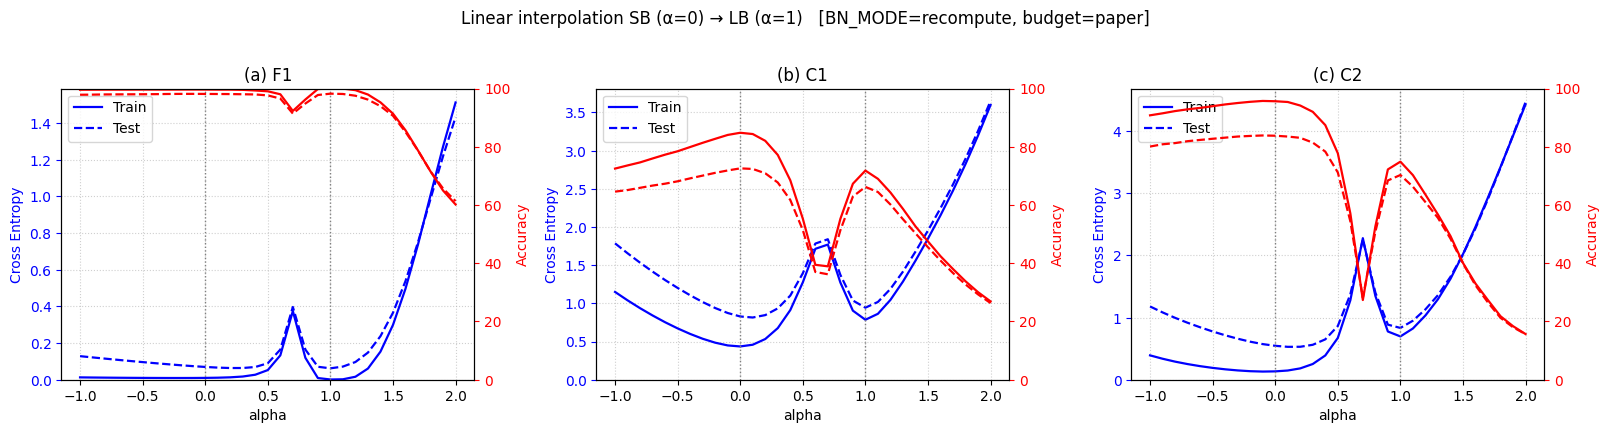

In [10]:
fig, axes = plt.subplots(1, len(NETWORKS), figsize=(5.4 * len(NETWORKS), 4.2))
axes = np.atleast_1d(axes)
for ax, net, letter in zip(axes, NETWORKS, "abcdef"):
    c = CURVES[net]
    ax.plot(ALPHAS, c["train_loss"], "b-",  lw=1.6, label="Train")
    ax.plot(ALPHAS, c["test_loss"],  "b--", lw=1.6, label="Test")
    ax.set_xlabel("alpha"); ax.set_ylabel("Cross Entropy", color="b")
    ax.set_ylim(bottom=0); ax.tick_params(axis="y", colors="b")
    ax.grid(True, ls=":", alpha=0.6)
    for x0 in (0, 1):
        ax.axvline(x0, color="gray", ls=":", lw=1)
    ax2 = ax.twinx()
    ax2.plot(ALPHAS, c["train_acc"], "r-",  lw=1.6)
    ax2.plot(ALPHAS, c["test_acc"],  "r--", lw=1.6)
    ax2.set_ylim(0, 100); ax2.set_ylabel("Accuracy", color="r"); ax2.tick_params(axis="y", colors="r")
    ax.legend(loc="upper left")
    ax.set_title(f"({letter}) {net}")
fig.suptitle(f"Linear interpolation SB (α=0) → LB (α=1)   [BN_MODE={BN_MODE}, budget={BUDGET}]", y=1.02)
fig.tight_layout()
fig.savefig(f"figure3_F1_C1_C2_{BUDGET}_{BN_MODE}.png", dpi=150, bbox_inches="tight")
plt.show()

### What to look for

1. **Endpoints:** train loss ≈ 0 at both $\alpha=0$ and $\alpha=1$; test loss lower at $\alpha=0$. (If LB's train loss is not near zero, it hasn't converged — the "sharpness" comparison is then confounded with "not finished". Raise `MAX_EPOCHS`.)
2. **Width:** how quickly the solid blue curve rises as you move away from each endpoint. The paper's claim is that it rises faster around $\alpha=1$.
3. **Between them:** a bump in train loss between 0 and 1 means the two solutions are in different basins.

A subtle point to keep in mind while reading your plot: moving from $\alpha=1$ to $\alpha=1.1$ and from $\alpha=0$ to $\alpha=-0.1$ are steps of the *same Euclidean length* $0.1\,\|x^\star_\ell - x^\star_s\|$ in parameter space, but along **one particular direction** — the one connecting the two solutions. A 1-D slice can't tell you about the other $n-1$ directions (the paper itself notes LB minima are sharp only along a small subspace).

**Question for you before moving on:** many of the layers here are followed by BatchNorm. For such a layer, $\text{BN}(cW u) = \text{BN}(W u)$ for any $c>0$. Starting from the definition of "flat" in Section 2.1 (the function varies slowly in a large neighborhood), what does this invariance imply about whether flatness, measured in Euclidean balls in parameter space, can be a property of the *function* the network computes rather than of its *parametrization*?

## 7. Optional: the paper's sharpness metric (Metric 2.1, full space, $A = I_n$)

$$
\phi_{x,f}(\epsilon) = \frac{\max_{y\in\mathcal{C}_\epsilon} f(x+y) - f(x)}{1+f(x)}\times 100,
\qquad \mathcal{C}_\epsilon = \{y : |y_i| \le \epsilon\,(|x_i|+1)\}.
$$

The paper approximates the max with 10 iterations of L-BFGS-B. Here: 10 steps of **projected sign-gradient ascent** inside the box (the box is an $\ell_\infty$-type set, and sign-gradient is the steepest-ascent direction for $\ell_\infty$). It starts from a **random point in the box** — at a minimizer $\nabla f \approx 0$, so a step from $y=0$ would barely move. $f$ is the training loss on the fixed `EVAL_TRAIN_N` subset, with BN in eval mode. Numbers won't match Table 3 exactly (different optimizer for the inner max), but the SB/LB ratio is what to compare.

In [11]:
def sharpness_metric(net, regime, eps=1e-3, steps=10, bs=2000):
    data = DATA[DATASET_OF[net]]
    X, Y = data["Xtr"][data["eval_idx"]], data["ytr"][data["eval_idx"]]
    model = MODELS[net]().to(DEVICE)
    model.load_state_dict({k: v.to(DEVICE) for k, v in RESULTS[(net, regime)]["state_dict"].items()})
    model.eval()
    params = list(model.parameters())
    x0  = [p.detach().clone() for p in params]
    box = [eps * (p.abs() + 1) for p in x0]

    def loss(grad):
        model.zero_grad(set_to_none=True)
        tot = 0.0
        for s in range(0, len(Y), bs):
            with torch.set_grad_enabled(grad):
                l = F.cross_entropy(model(X[s:s + bs]), Y[s:s + bs], reduction="sum") / len(Y)
                if grad:
                    l.backward()
            tot += l.item()
        return tot

    f0 = loss(False)
    fmax = f0
    with torch.no_grad():
        y = [torch.empty_like(b).uniform_(-1, 1) * b for b in box]
    for _ in range(steps):
        with torch.no_grad():
            for p, a, yi in zip(params, x0, y):
                p.copy_(a + yi)
        fmax = max(fmax, loss(True))
        with torch.no_grad():
            for p, yi, b in zip(params, y, box):
                yi.add_(0.5 * b * p.grad.sign())
                yi.copy_(torch.minimum(torch.maximum(yi, -b), b))   # project onto the box
    with torch.no_grad():
        for p, a, yi in zip(params, x0, y):
            p.copy_(a + yi)
    fmax = max(fmax, loss(False))
    return 100.0 * (fmax - f0) / (1.0 + f0)

print(f"{'net':4s} {'eps':>7s} {'SB':>10s} {'LB':>10s}")
for net in NETWORKS:
    for eps in (1e-3, 5e-4):
        torch.manual_seed(0)
        sb, lb = sharpness_metric(net, "SB", eps), sharpness_metric(net, "LB", eps)
        print(f"{net:4s} {eps:7.0e} {sb:10.2f} {lb:10.2f}")

net      eps         SB         LB
F1     1e-03     244.37    4468.62
F1     5e-04      18.67    1653.74
C1     1e-03     589.98    1293.87
C1     5e-04     117.21     561.66
C2     1e-03   12357.34   49824.03
C2     5e-04    3228.43    1243.02


## 8. Things to try (each one tests a piece of the paper's story)

1. **Curvature along the path.** Using `interpolate_state` + `recalibrate_bn`, evaluate the train loss at $\alpha\in\{-h,0,h\}$ and $\{1-h,1,1+h\}$ with $h=0.01$, and form the finite difference $\big(f(\alpha+h)-2f(\alpha)+f(\alpha-h)\big)/h^2$. Derive what this estimates in terms of $\nabla^2 f$ and the direction $d = x^\star_\ell - x^\star_s$ — and then say why comparing the value at $\alpha=0$ with the one at $\alpha=1$ is fair (hint: what is the step length at each end?).
2. **`SAME_INIT = True`.** Train LB from the *same* initialization as SB. Is there still a barrier between them? If not, are they "the same basin", and does the LB end still look sharper?
3. **Is it the batch size, or the step count / noise scale?** The paper keeps $\text{lr}=10^{-3}$ for both regimes, so LB takes ~20× fewer steps per epoch with the same step size. A common heuristic says SGD's noise scale is roughly $\text{lr}/B$. Rerun LB with a larger learning rate (with a few epochs of linear warmup) and see how much of the test gap — and of the sharpness — survives. This is the line of work that followed the paper (Goyal et al. 2017; Hoffer et al. 2017; Smith & Le 2018).
4. **Break the metric on purpose.** In F1, multiply the weights of one `Linear` layer that feeds a BN layer by $c=10$. The function is unchanged (why, exactly, from the BN formula?). Recompute `sharpness_metric`. This is the argument of Dinh et al. (2017), *Sharp Minima Can Generalize for Deep Nets*. Notice that Metric 2.1's box scales with $|x_i|+1$ — think about whether that partially defends against this or not.